# Apprentissage supervisé — TP complet

Compilation de toutes les fonctions de `utils.py` et des jeux de données du dossier `data/`
(SAheart, Adult), organisée par séance.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import utils
utils.style()
GRAINE = 42

## 0. Données

### SAheart (maladie coronarienne)

In [2]:
print(open("data/SAheart-info.txt", encoding="utf-8").read())

A retrospective sample of males in a heart-disease high-risk region
of the Western Cape, South Africa. There are roughly two controls per
case of CHD. Many of the CHD positive men have undergone blood
pressure reduction treatment and other programs to reduce their risk
factors after their CHD event. In some cases the measurements were
made after these treatments. These data are taken from a larger
dataset, described in  Rousseauw et al, 1983, South African Medical
Journal. 

sbp		systolic blood pressure
tobacco		cumulative tobacco (kg)
ldl		low densiity lipoprotein cholesterol
adiposity
famhist		family history of heart disease (Present, Absent)
typea		type-A behavior
obesity
alcohol		current alcohol consumption
age		age at onset
chd		response, coronary heart disease

To read into R:
read.table("http://www-stat.stanford.edu/~tibs/ElemStatLearn/datasets/SAheart.data",
	sep=",",head=T,row.names=1)



In [3]:
df = utils.load_saheart()
print(df.shape)
print(df.head().to_string())
print()
print(df.describe().round(2).to_string())
print("\nRépartition chd :", df["chd"].value_counts().to_dict())

(462, 10)
           sbp  tobacco   ldl  adiposity  famhist  typea  obesity  alcohol  age  chd
row.names                                                                           
1          160    12.00  5.73      23.11        1     49    25.30    97.20   52    1
2          144     0.01  4.41      28.61        0     55    28.87     2.06   63    1
3          118     0.08  3.48      32.28        1     52    29.14     3.81   46    0
4          170     7.50  6.41      38.03        1     51    31.99    24.26   58    1
5          134    13.60  3.50      27.78        1     60    25.99    57.34   49    1

          sbp  tobacco     ldl  adiposity  famhist   typea  obesity  alcohol     age     chd
count  462.00   462.00  462.00     462.00   462.00  462.00   462.00   462.00  462.00  462.00
mean   138.33     3.64    4.74      25.41     0.42   53.10    26.04    17.04   42.82    0.35
std     20.50     4.59    2.07       7.78     0.49    9.82     4.21    24.48   14.61    0.48
min    101.00     0.00

### Adult (Census Income 1994)

In [4]:
adult = utils.load_adult()
print(adult.shape)
print(adult.head().to_string())
print("\nTaux de positifs (income) :", round(adult["income"].mean(), 3))
print("Manquants :", adult.isna().sum()[adult.isna().sum() > 0].to_dict())

(10000, 13)
   age workclass   education      marital-status       occupation    relationship   race     sex  capital-gain  capital-loss  hours-per-week native-country  income
0   27   Private  Assoc-acdm       Never-married            Sales   Not-in-family  White    Male             0             0              52  United-States       0
1   32   Private     5th-6th           Separated  Farming-fishing  Other-relative  White    Male             0             0              60         Mexico       0
2   40   Private     HS-grad            Divorced    Other-service       Unmarried  White  Female             0             0              36  United-States       0
3   43   Private     HS-grad  Married-civ-spouse  Exec-managerial         Husband  White    Male             0             0              44  United-States       0
4   40   Private  Assoc-acdm            Divorced   Prof-specialty   Not-in-family  White  Female             0             0              40  United-States       0

Tau

## 1. Règle de Bayes et coûts asymétriques

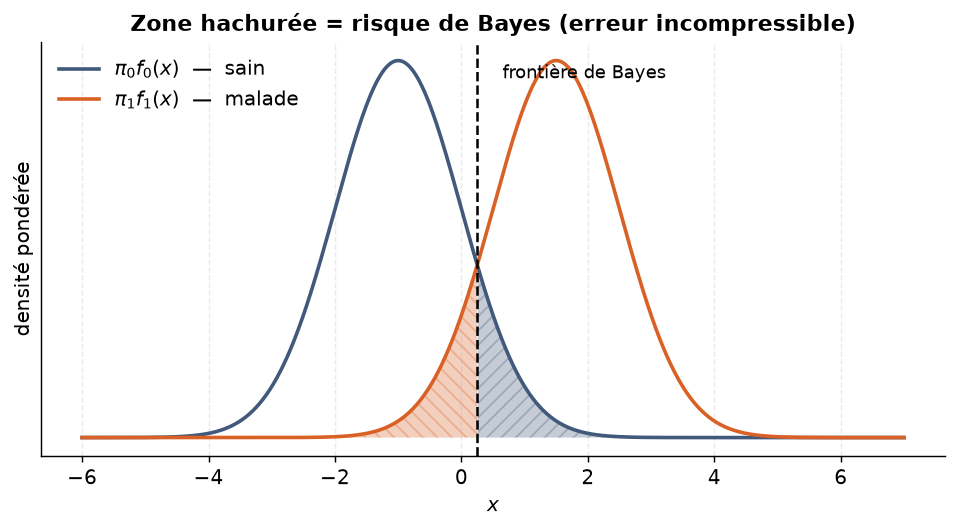

In [5]:
utils.plot_bayes_rule()

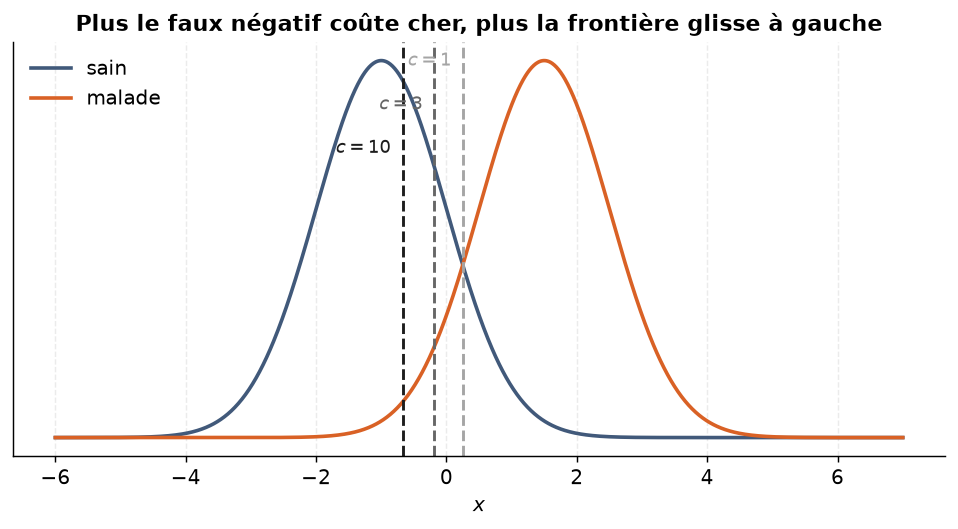

In [6]:
utils.plot_couts_asymetriques()

## 2. Sur-apprentissage et compromis biais-variance

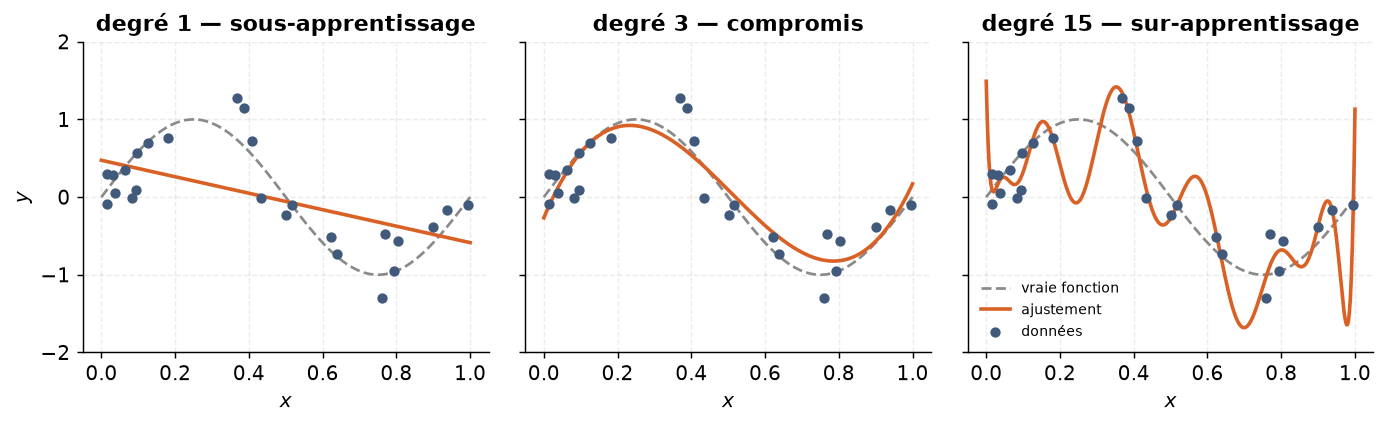

In [7]:
utils.plot_sur_apprentissage()

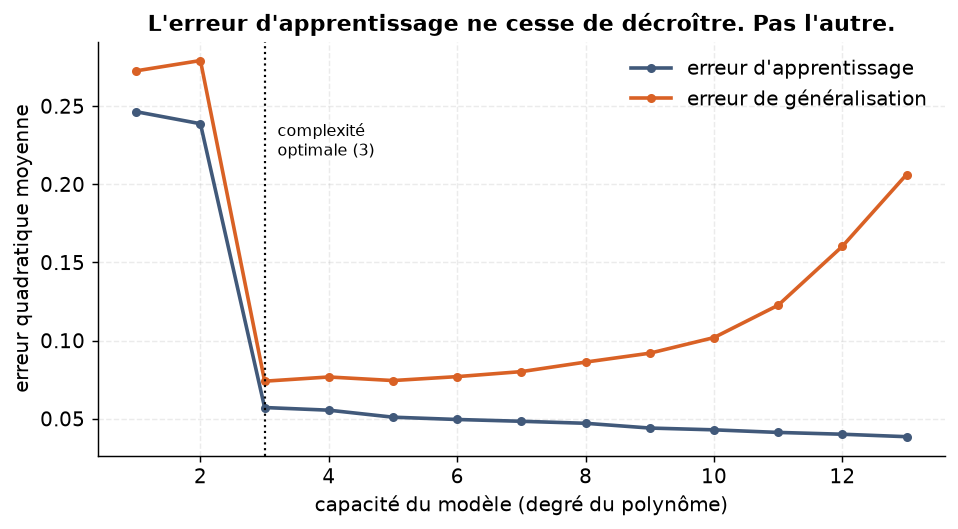

In [8]:
utils.plot_courbe_en_u()

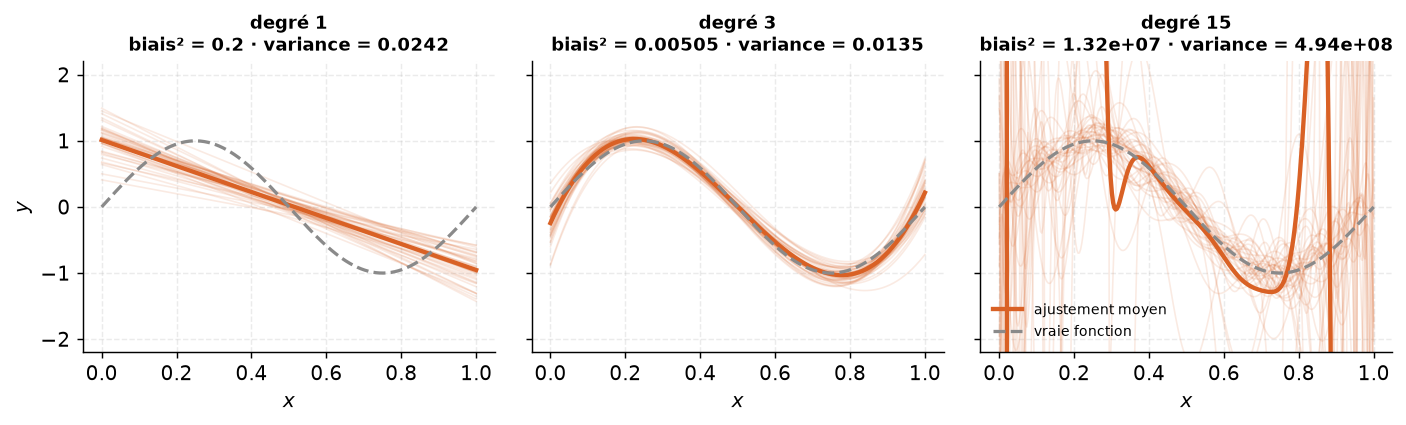

In [9]:
utils.plot_biais_variance()

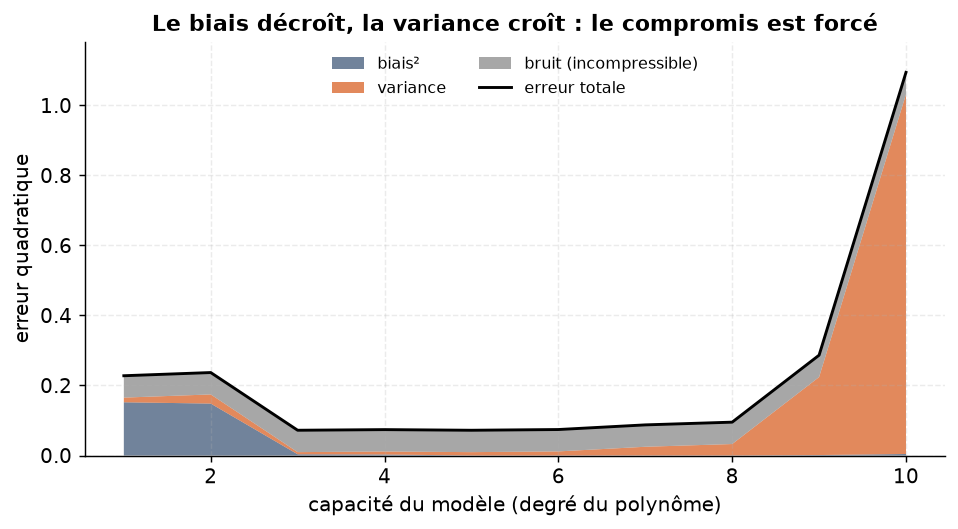

In [10]:
utils.plot_decomposition_biais_variance()

## 3. Découpage des données, validation croisée, fléau de la dimension

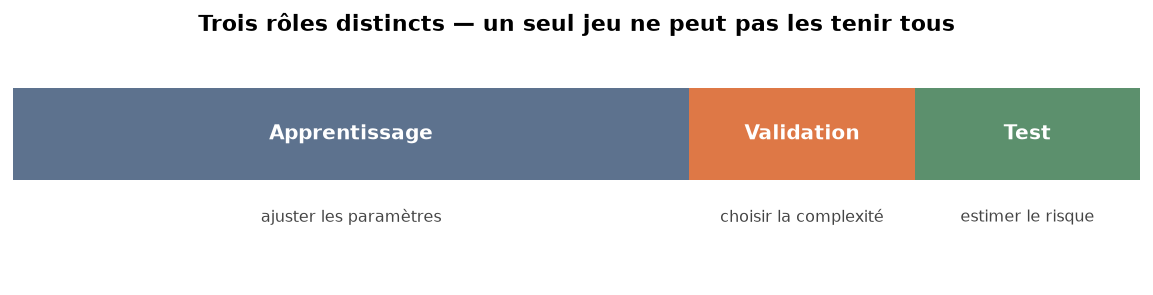

In [11]:
utils.plot_decoupage_donnees()

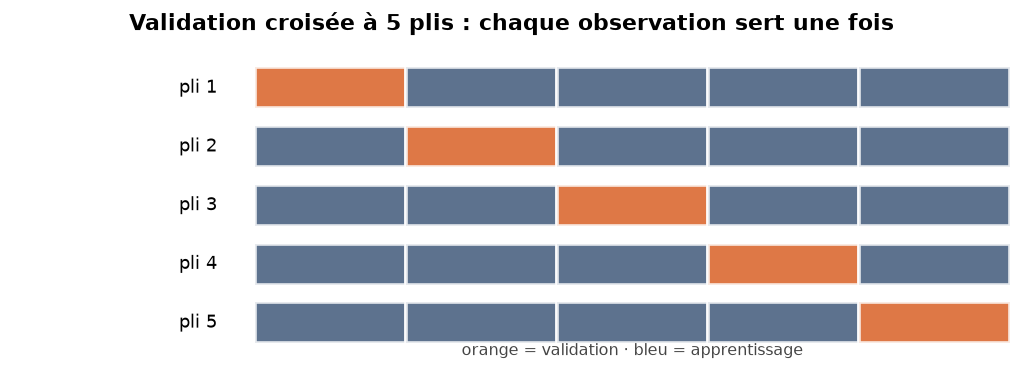

In [12]:
utils.plot_validation_croisee()

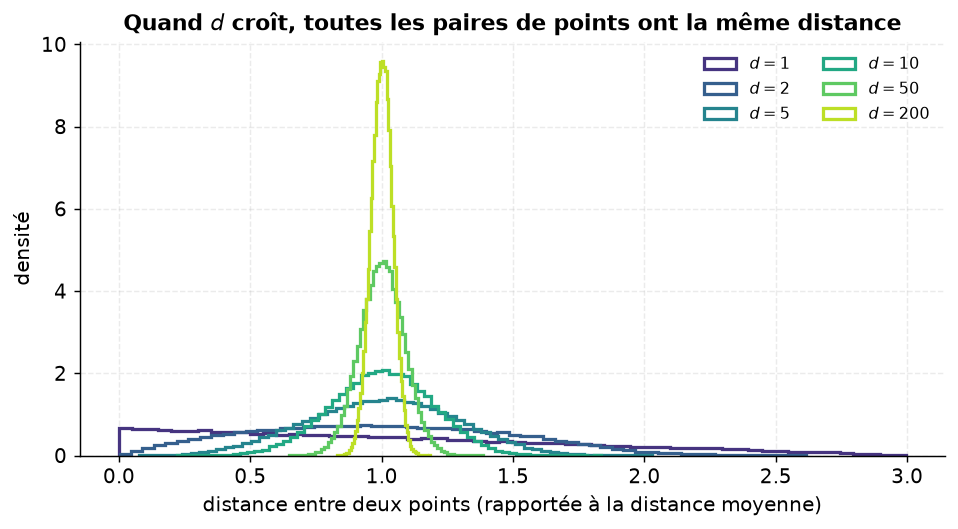

In [13]:
utils.plot_fleau_dimension()

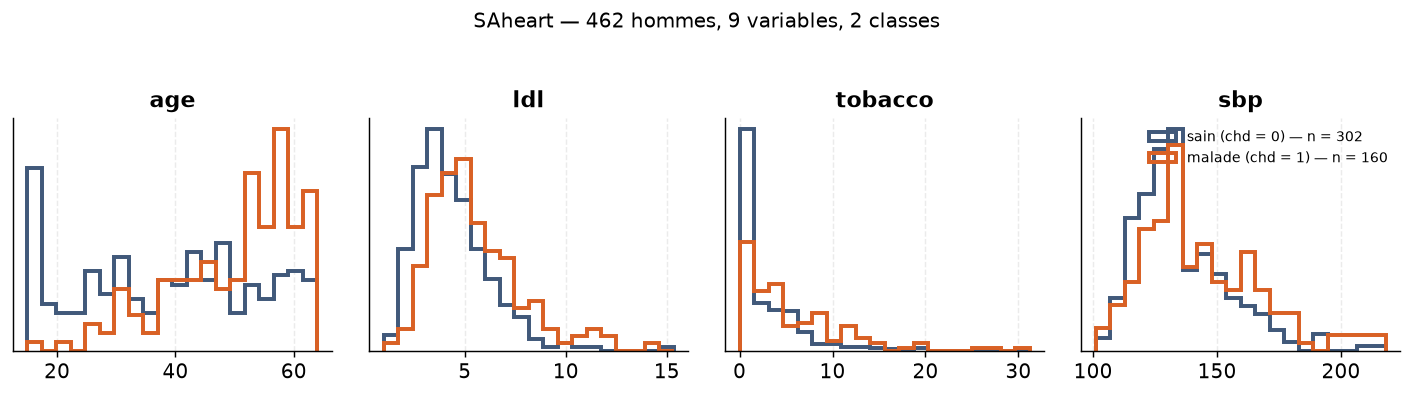

In [14]:
utils.plot_saheart_apercu()

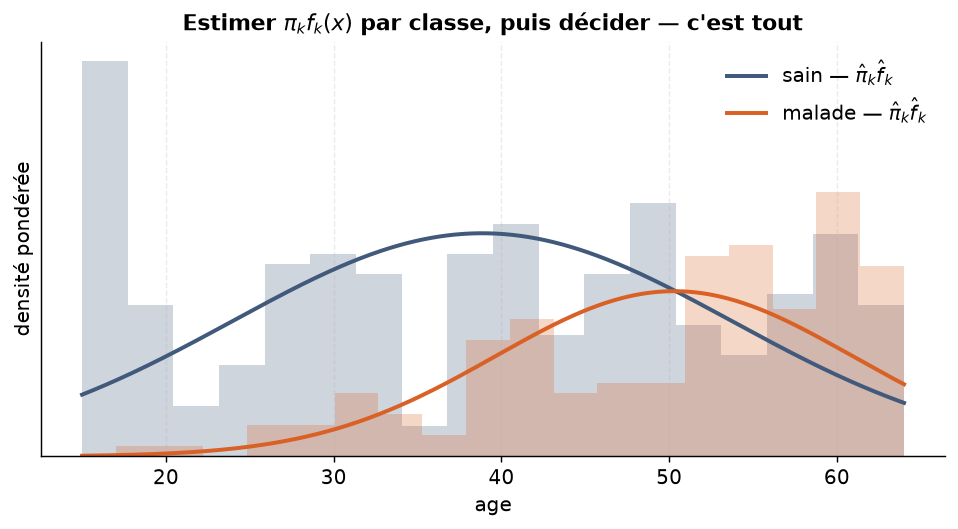

In [15]:
utils.plot_bayes_naif_1d()

## 4. Frontières de décision

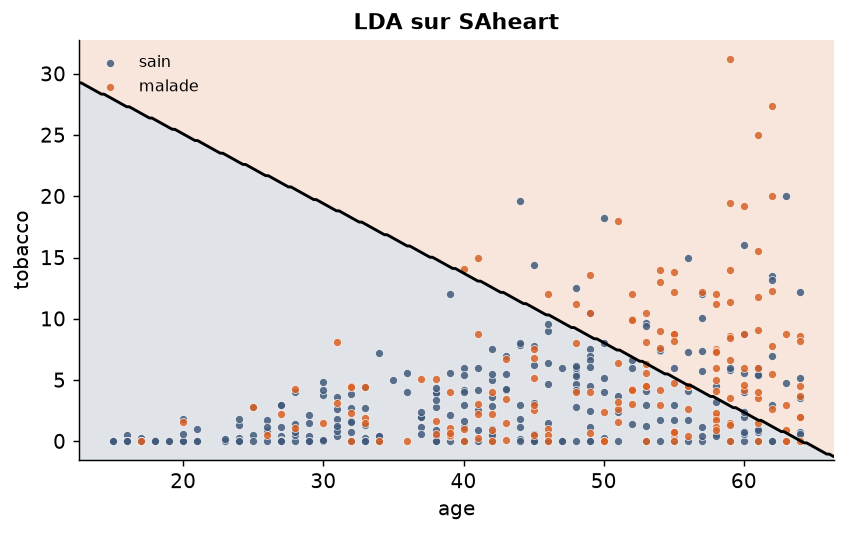

In [16]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB

X2, y2 = utils.saheart_xy(variables=("age", "tobacco"))
lda = LinearDiscriminantAnalysis().fit(X2, y2)
utils.plot_decision_boundary(lda, X2, y2, noms=("age", "tobacco"), titre="LDA sur SAheart")

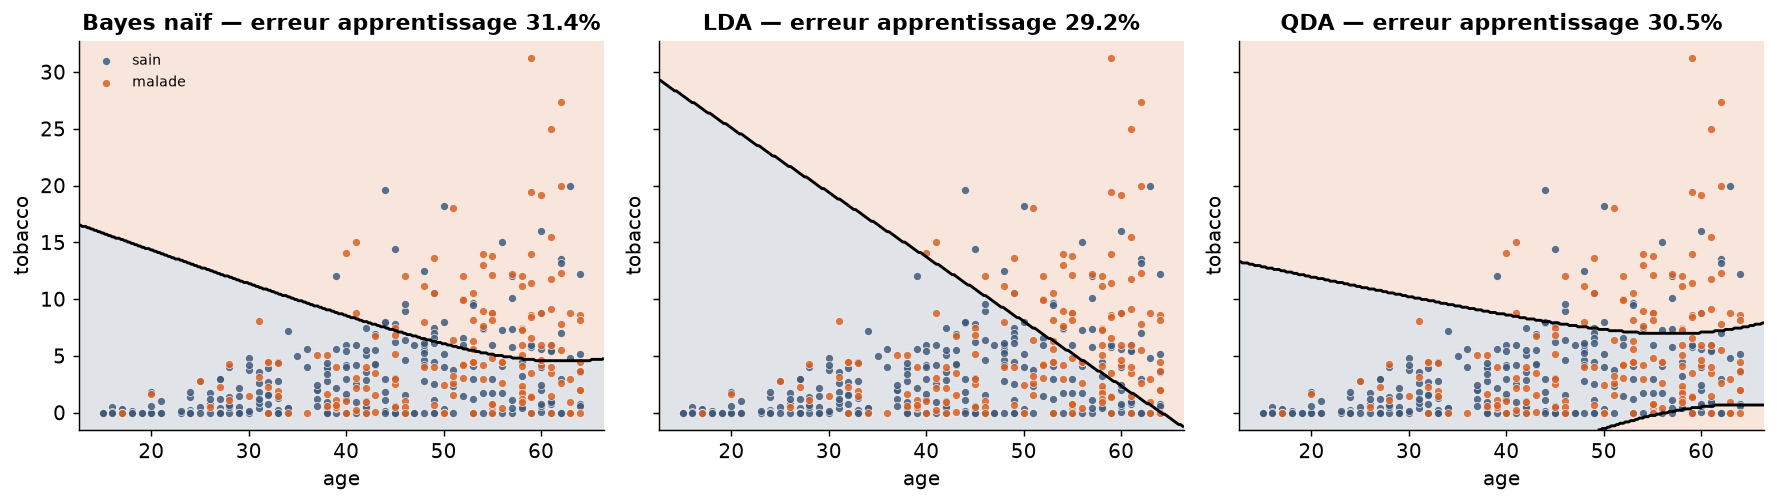

In [17]:
utils.comparer_frontieres(
    {"Bayes naïf": GaussianNB(),
     "LDA": LinearDiscriminantAnalysis(),
     "QDA": QuadraticDiscriminantAnalysis()},
    X2, y2, noms=("age", "tobacco"))

## 5. Loi normale multivariée, LDA, QDA

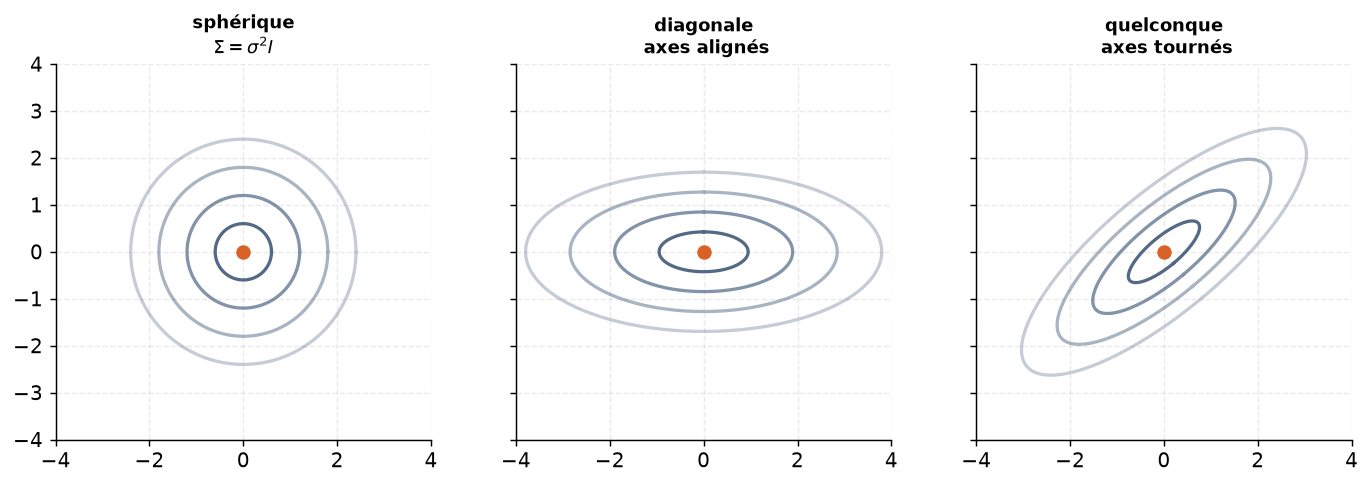

In [18]:
utils.plot_gaussienne_bivariee()

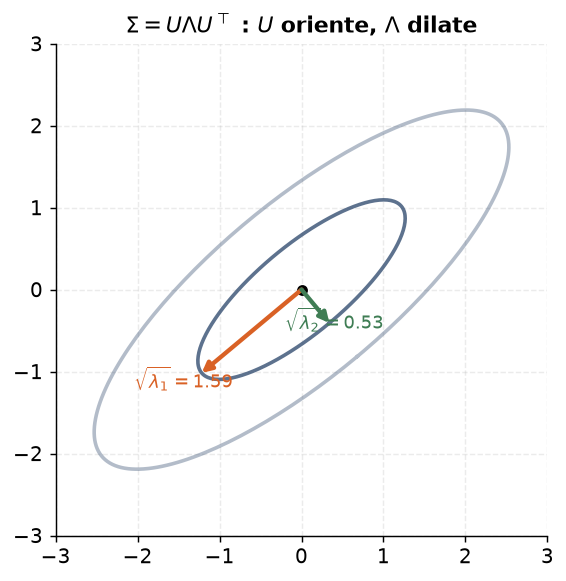

In [19]:
utils.plot_decomposition_covariance()

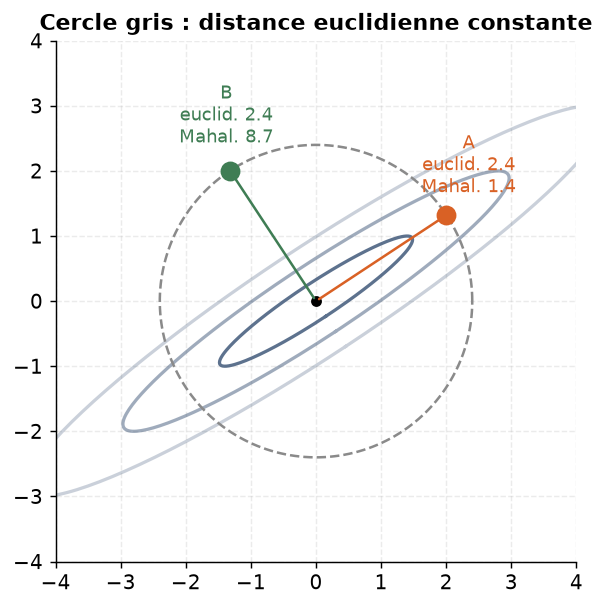

In [20]:
utils.plot_mahalanobis()

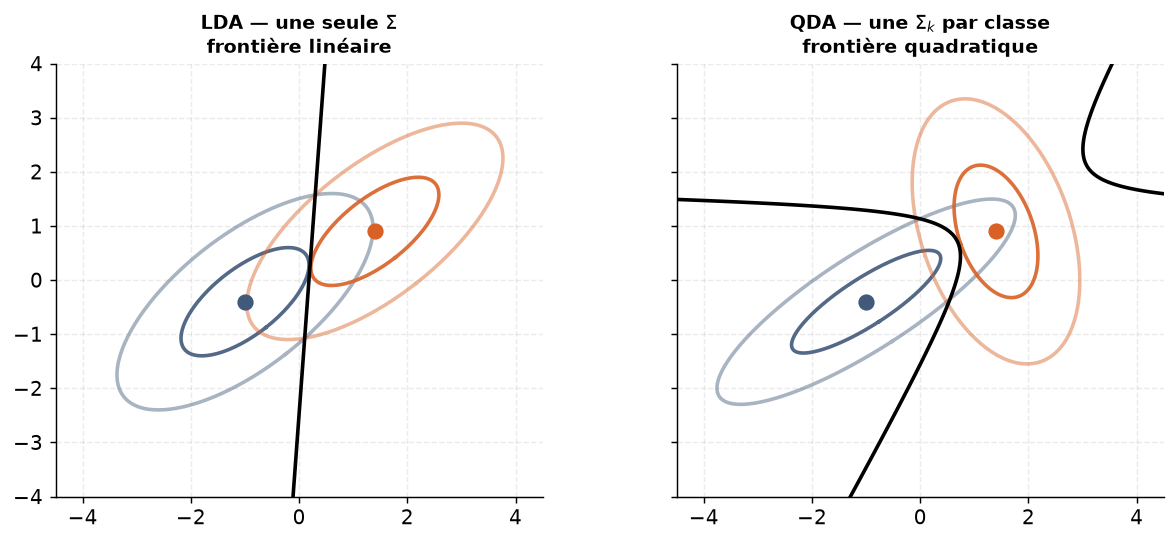

In [21]:
utils.plot_lda_vs_qda_modele()

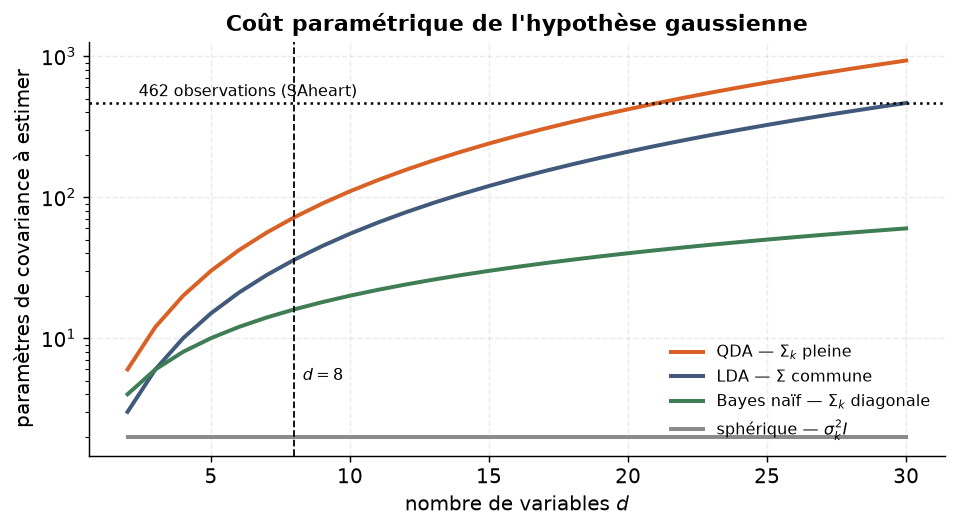

In [22]:
utils.plot_complexite_parametrique()

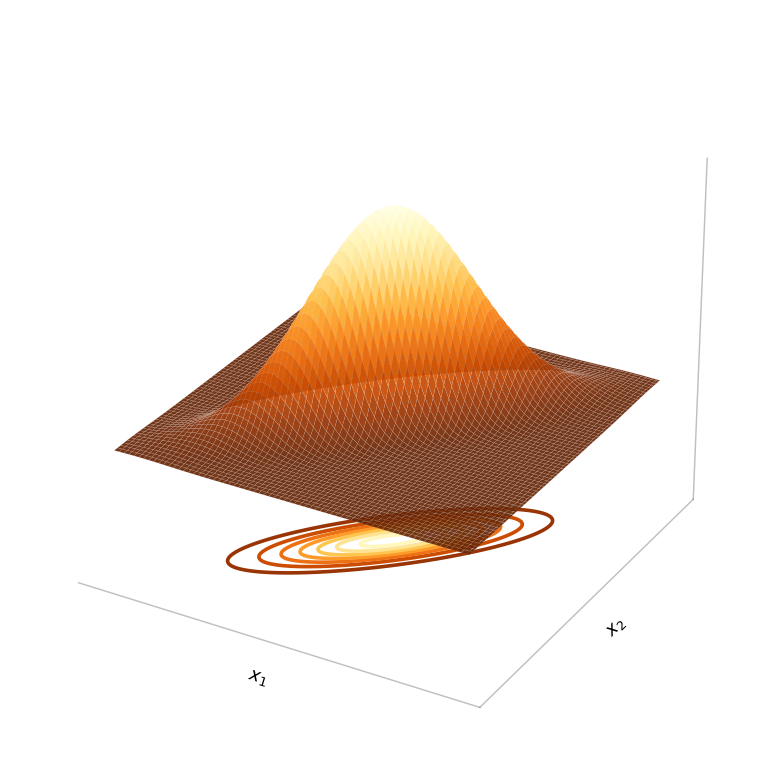

In [23]:
utils.plot_gaussienne_3d()

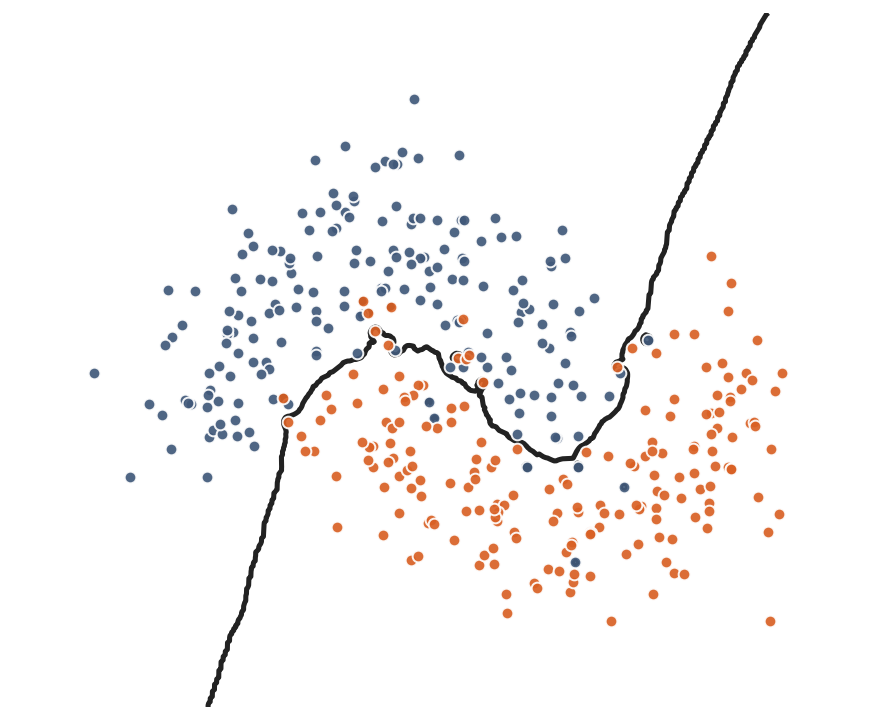

In [24]:
utils.plot_classification_2d()

## 6. Méthodes locales : Parzen et k plus proches voisins

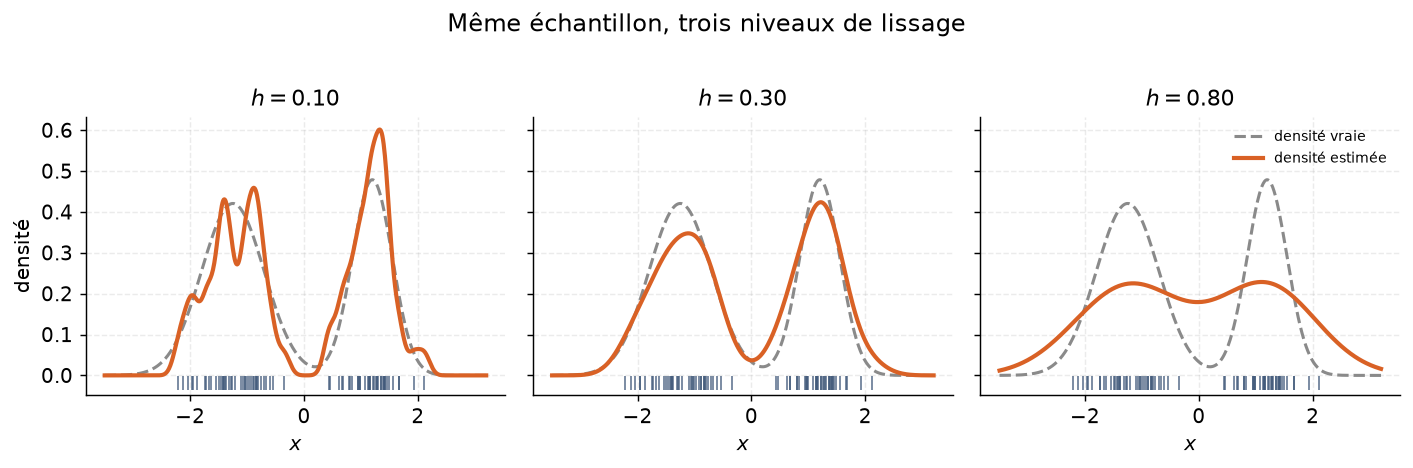

In [25]:
utils.plot_parzen_1d()

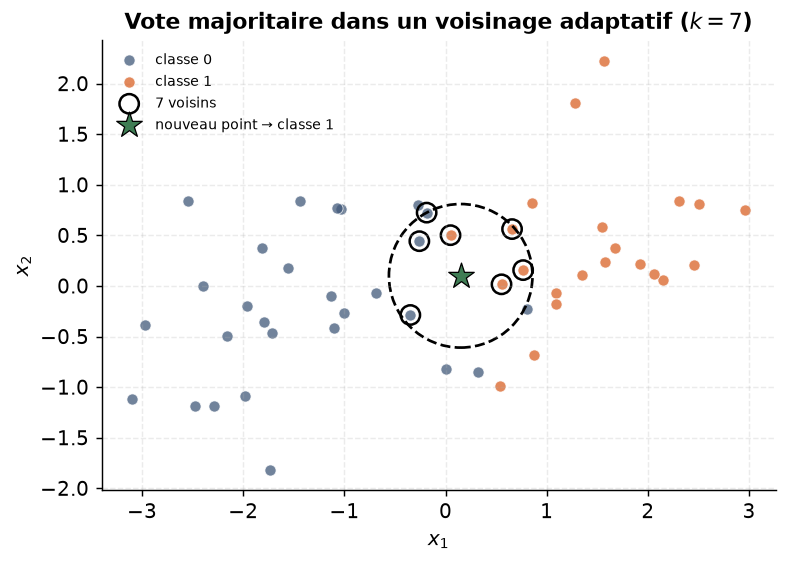

In [26]:
utils.plot_voisinage_kppv()

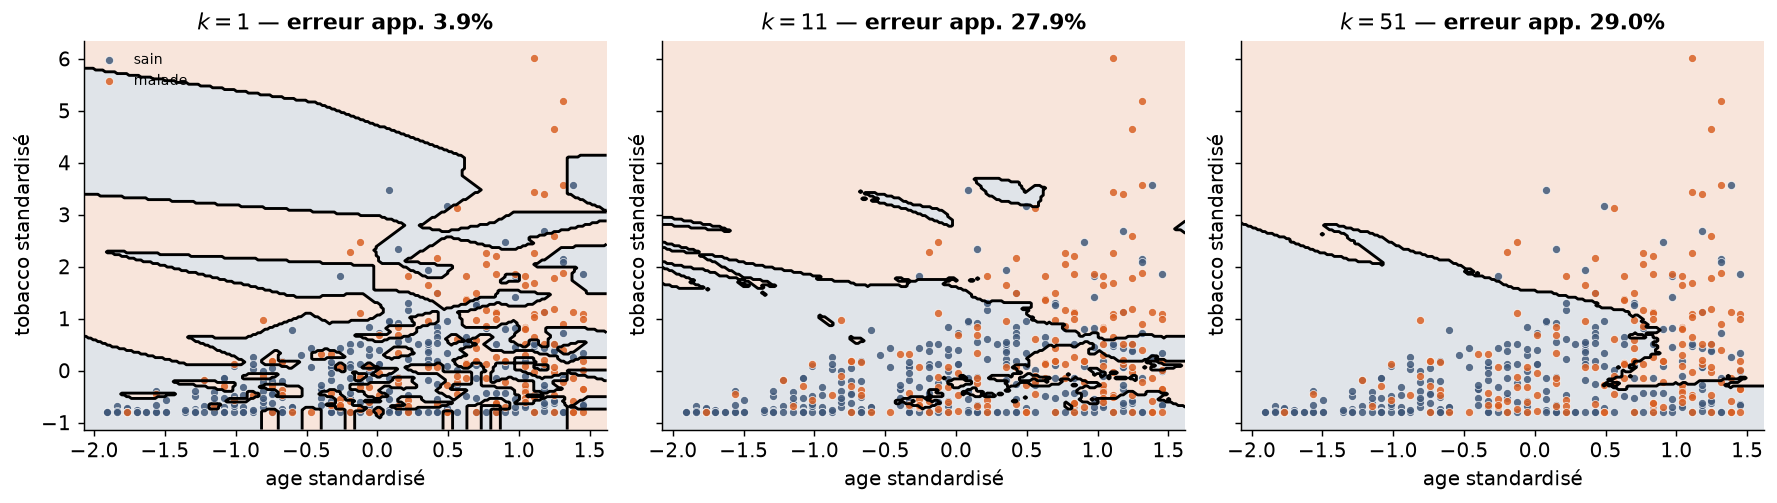

In [27]:
utils.plot_frontieres_kppv()

### Standardisation et k-PPV (SAheart)

In [28]:
X, y = utils.saheart_xy()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=GRAINE)

modele_brut = KNeighborsClassifier(n_neighbors=15)
modele_standardise = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15))

score_brut = cross_val_score(modele_brut, X, y, cv=cv, scoring="balanced_accuracy").mean()
score_standardise = cross_val_score(modele_standardise, X, y, cv=cv, scoring="balanced_accuracy").mean()
print(f"brut : {score_brut:.3f}")
print(f"standardisé : {score_standardise:.3f}")

brut : 0.599
standardisé : 0.633


### Choix de k par validation croisée

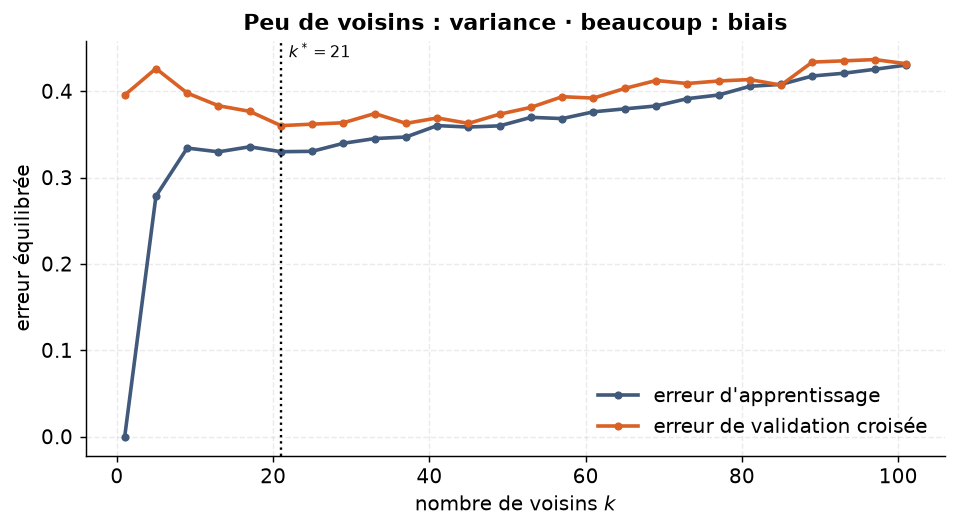

In [29]:
k_values = np.arange(1, 102, 4)
err_train, err_val = [], []
for k in k_values:
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    r = cross_validate(m, X, y, cv=cv, scoring="balanced_accuracy", return_train_score=True)
    err_train.append(1 - r["train_score"].mean())
    err_val.append(1 - r["test_score"].mean())
utils.plot_courbe_kppv(k_values, err_train, err_val)

### Effet de variables de bruit

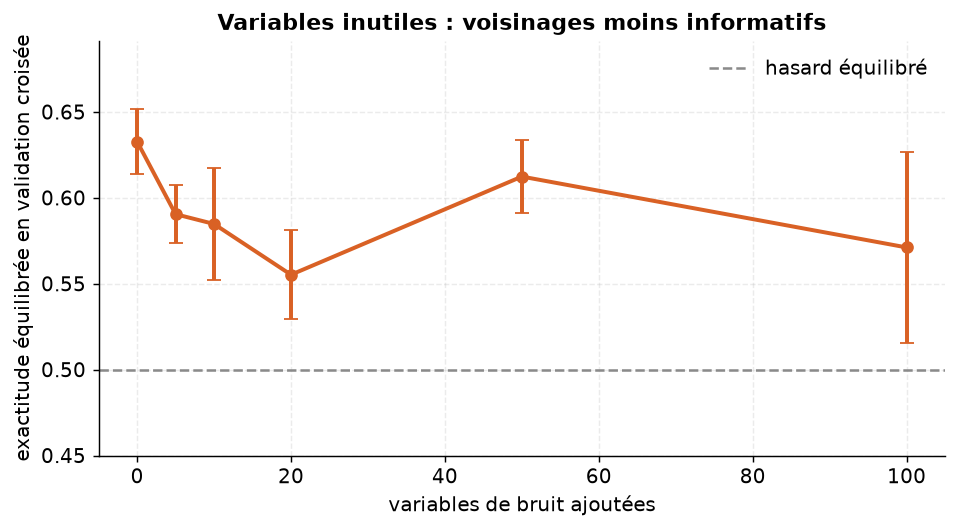

In [30]:
rng = np.random.default_rng(GRAINE)
n_noise = [0, 5, 10, 20, 50, 100]
scores, disp = [], []
for p in n_noise:
    Xb = np.hstack([X, rng.normal(size=(len(X), p))])
    s = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
                        Xb, y, cv=cv, scoring="balanced_accuracy")
    scores.append(s.mean()); disp.append(s.std())
utils.plot_bruit_kppv(n_noise, scores, disp)

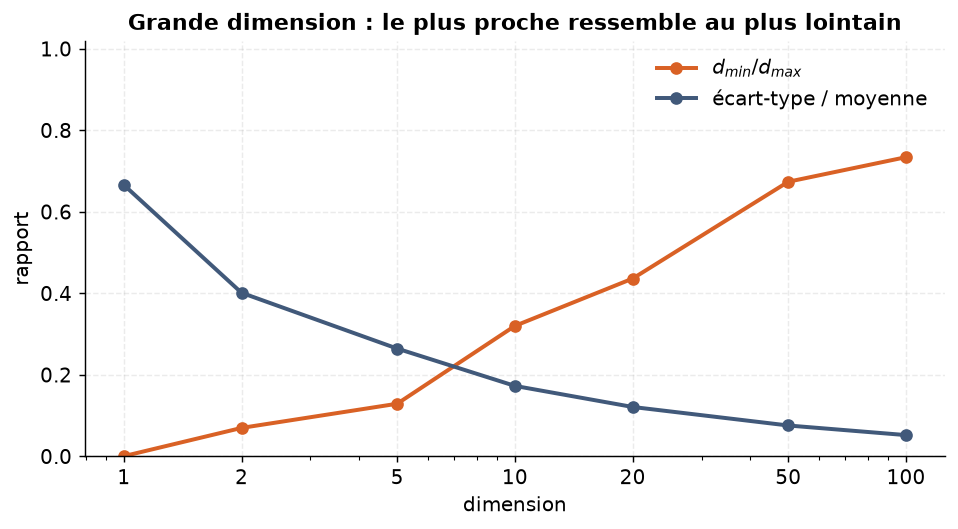

In [31]:
utils.plot_concentration_distances()

## 7. Arbres de décision (CART)

In [32]:
Xa, ya, noms = utils.adult_xy()
print(Xa.shape, noms)

(10000, 12) ['age', 'workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country']


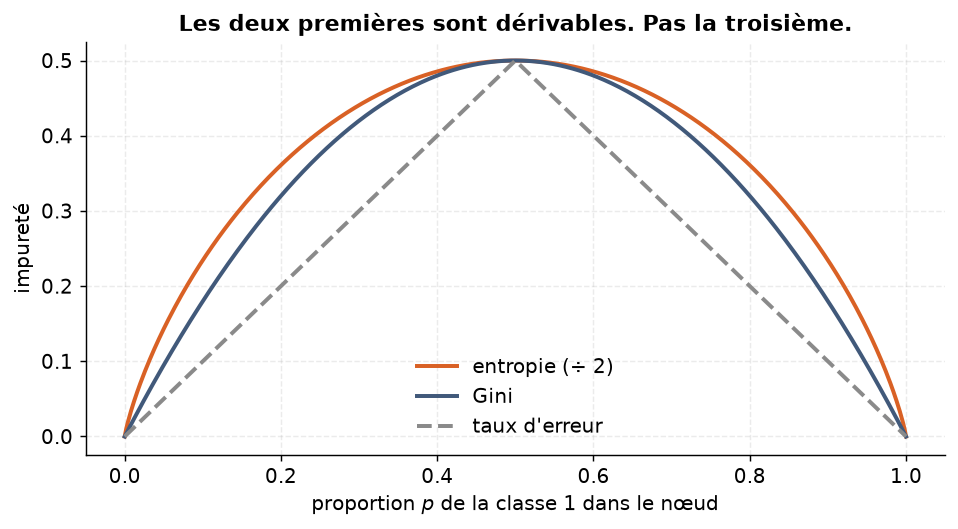

In [33]:
utils.plot_impuretes()

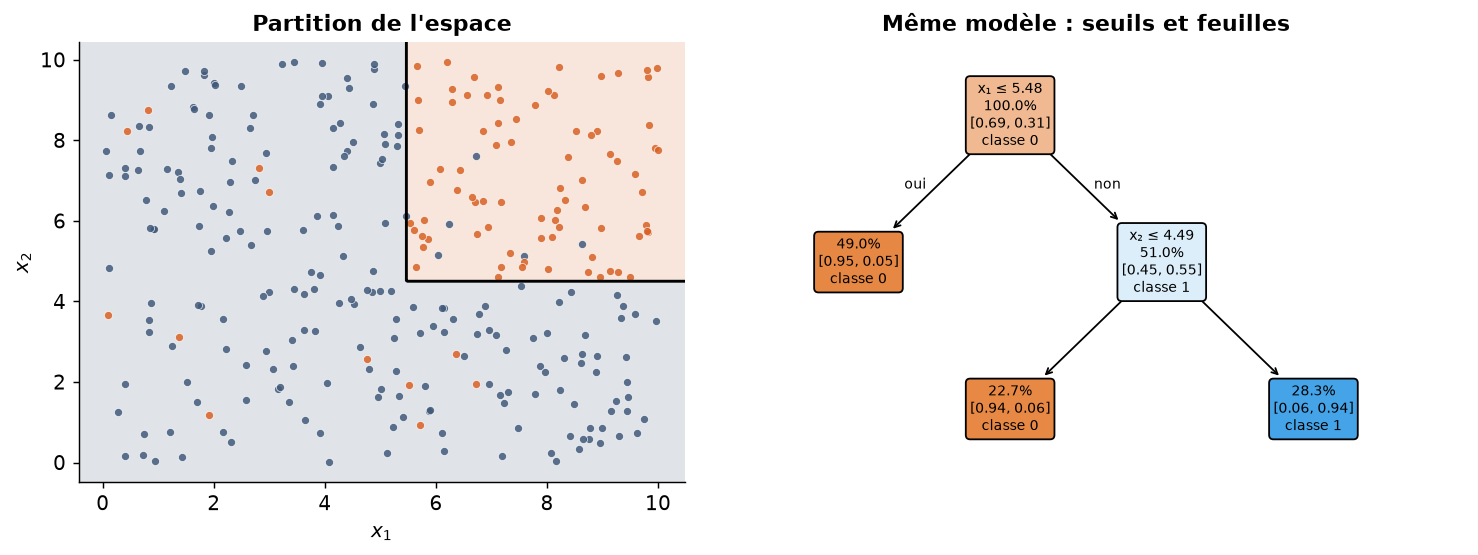

In [34]:
utils.plot_partition_recursive()

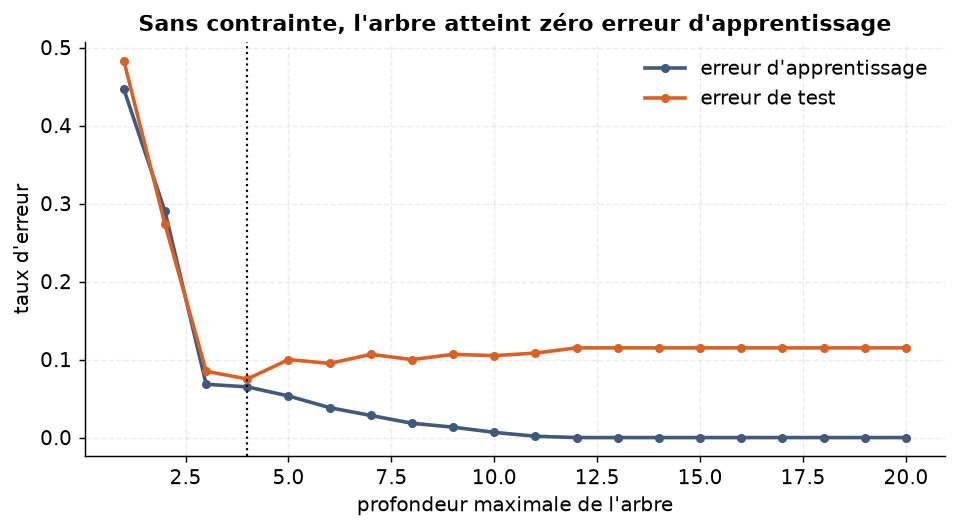

In [35]:
utils.plot_sur_apprentissage_arbre()

In [36]:
res = utils.chemin_elagage(*utils._donnees_2d())
print(type(res))

<class 'tuple'>


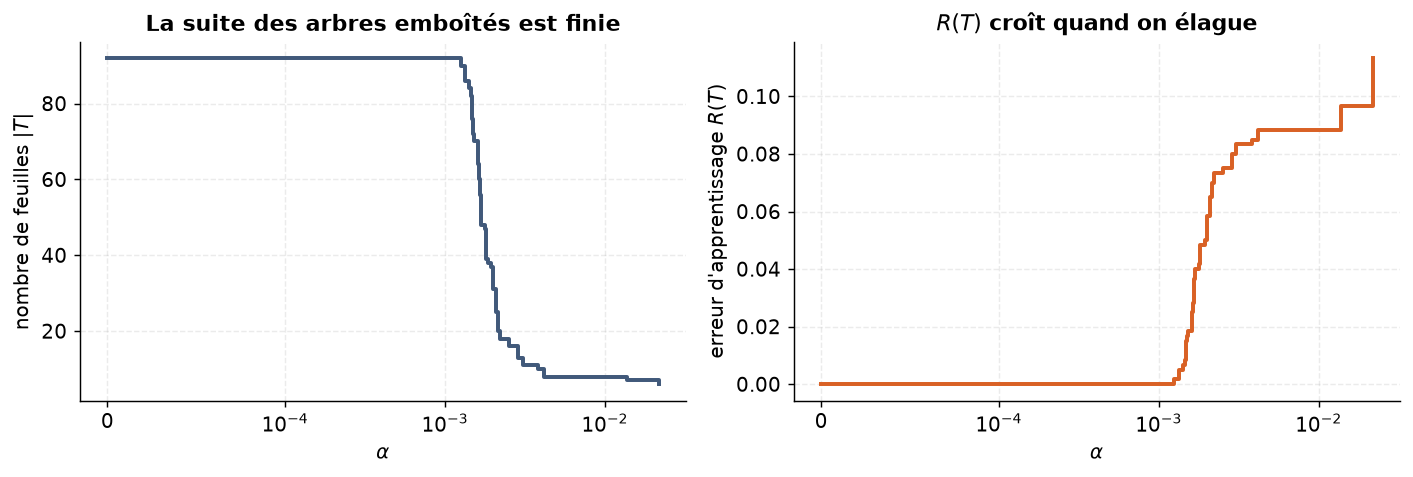

In [37]:
utils.plot_chemin_elagage()

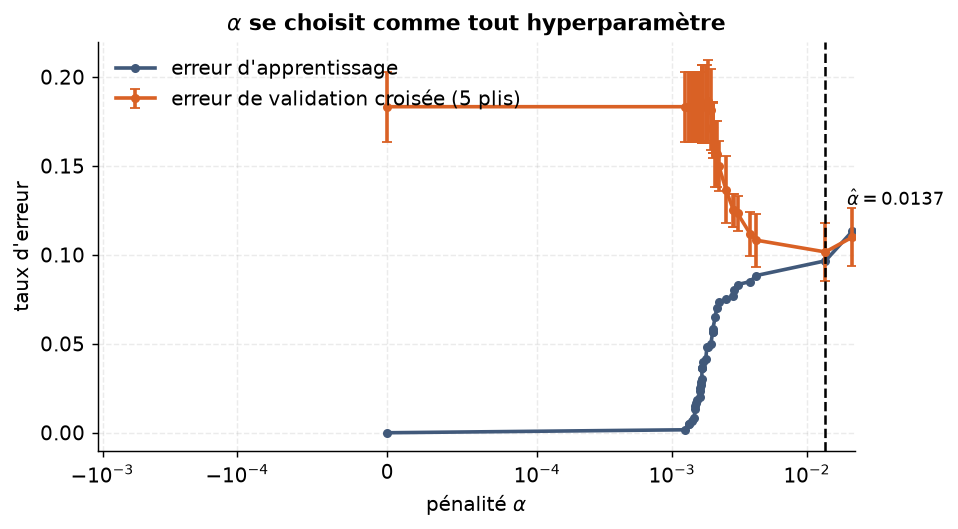

In [38]:
utils.plot_choix_alpha()

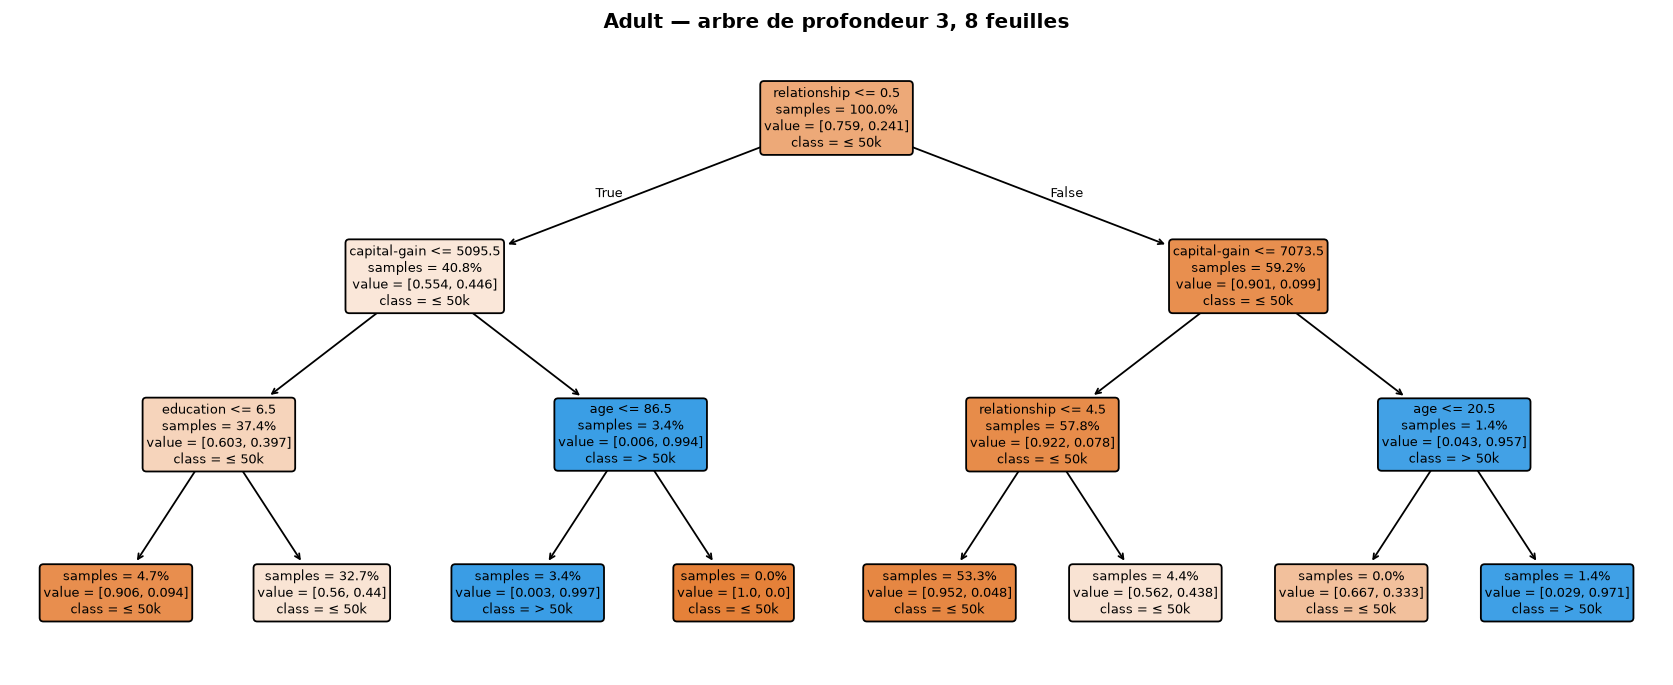

In [39]:
utils.plot_arbre_adult()

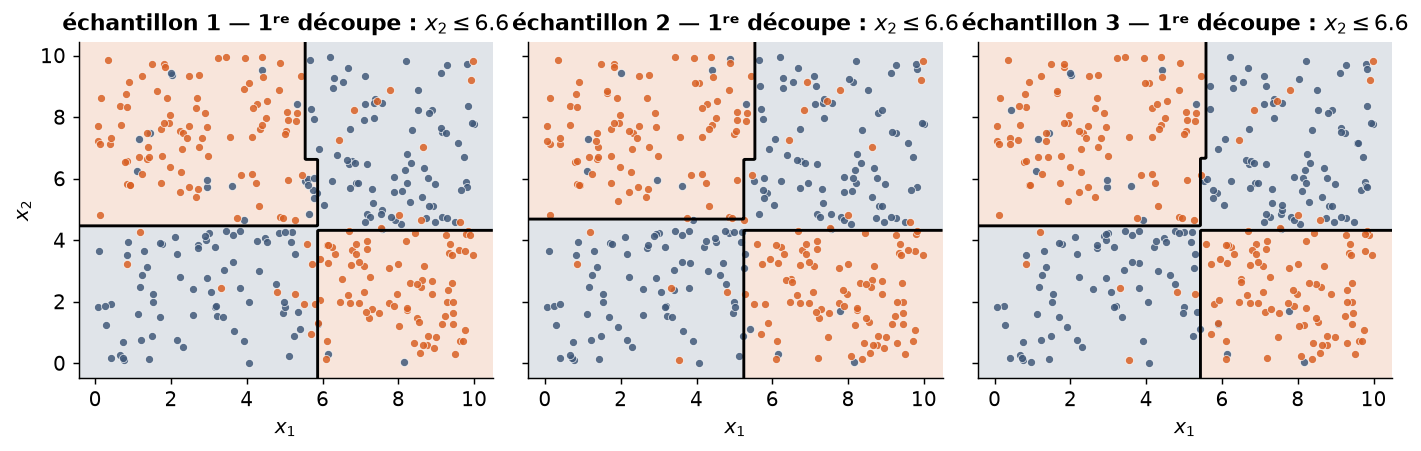

In [40]:
utils.plot_instabilite()

## 8. Méthodes d'ensemble : bagging, forêts aléatoires, boosting

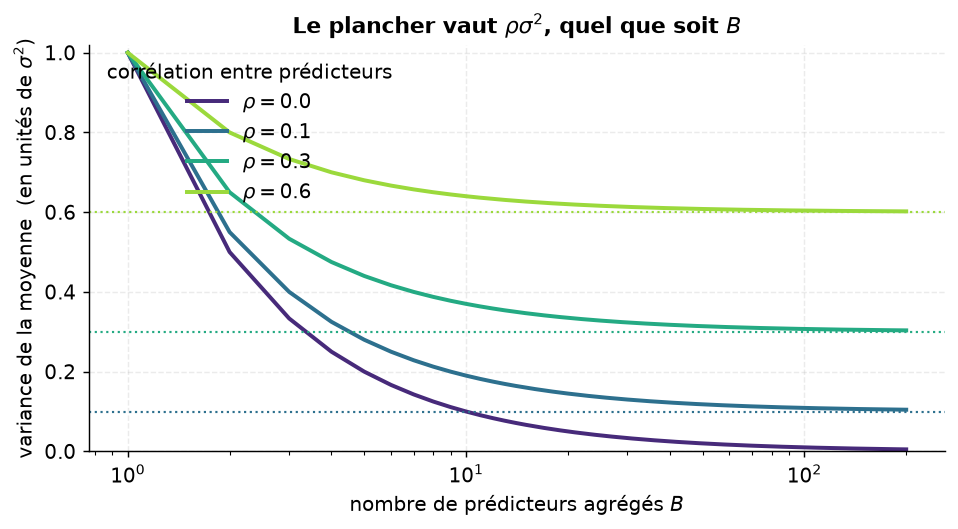

In [41]:
utils.plot_variance_moyenne()

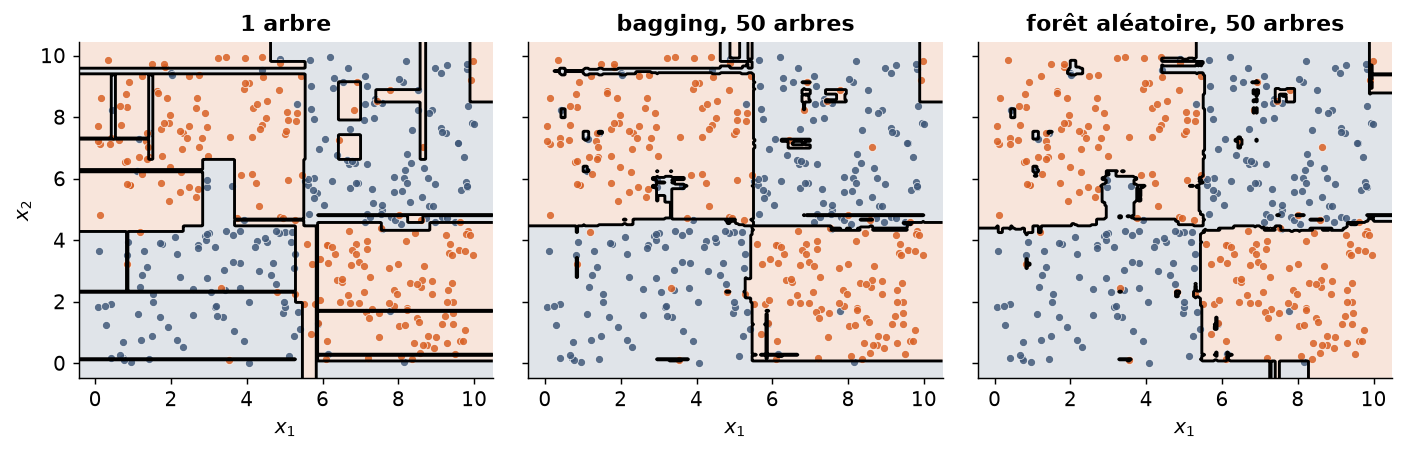

In [42]:
utils.plot_bagging_lissage()

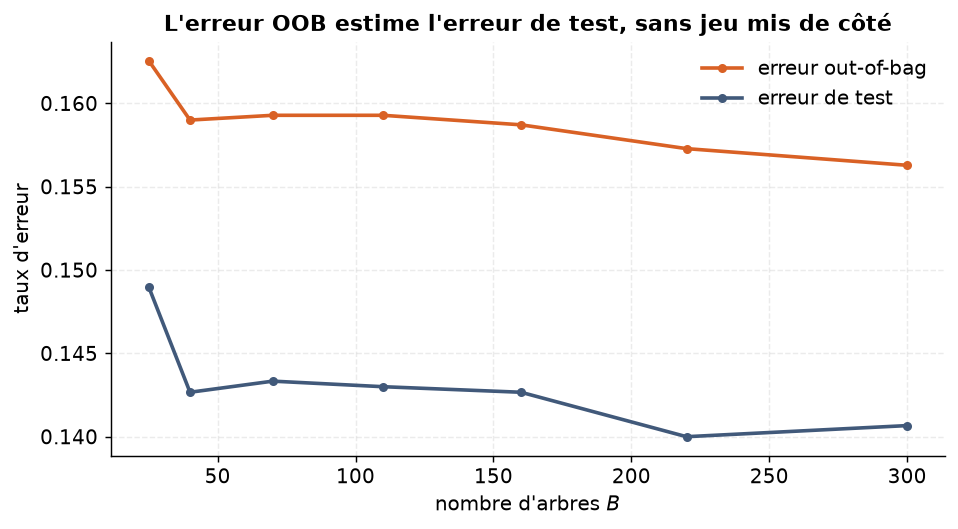

In [43]:
utils.plot_oob()

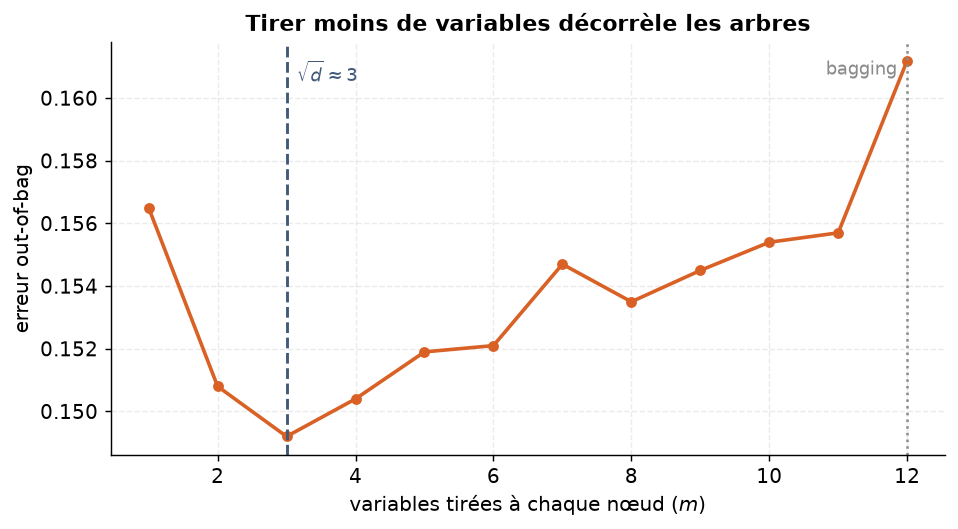

In [44]:
utils.plot_mtry()

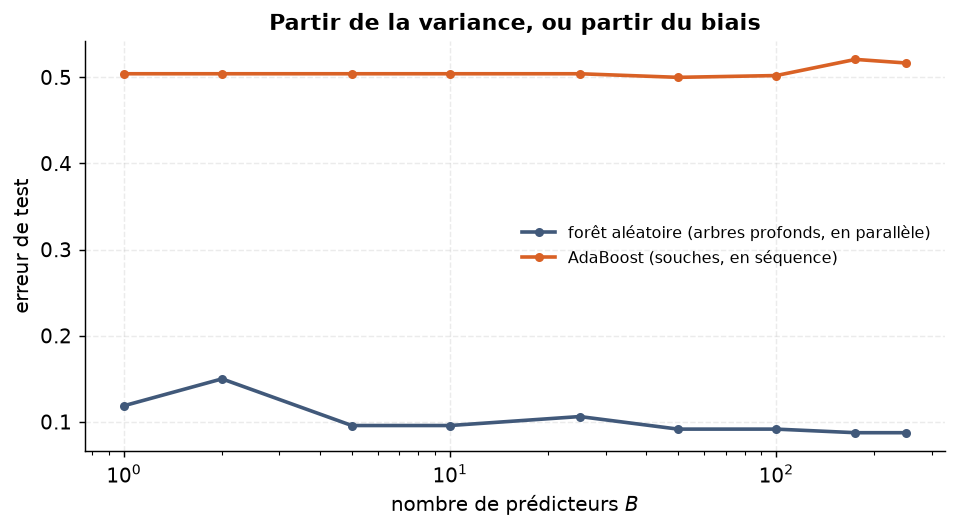

In [45]:
utils.plot_boosting()

## 9. Équité algorithmique (Adult)

In [46]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

adult = utils.load_adult()
sexe = adult["sex"].to_numpy()
Xtr, Xte, ytr, yte, gtr, gte = train_test_split(Xa, ya, sexe, test_size=0.3,
                                                stratify=ya, random_state=GRAINE)
foret = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=GRAINE, n_jobs=-1)
foret.fit(Xtr, ytr)
tableau = utils.metriques_equite(yte, foret.predict(Xte), gte)
print(tableau.round(3).to_string())

             n  taux de base  taux de sélection    TPR    FPR    VPP
Female  1003.0         0.106              0.068  0.481  0.019  0.750
Male    1997.0         0.308              0.228  0.586  0.069  0.792


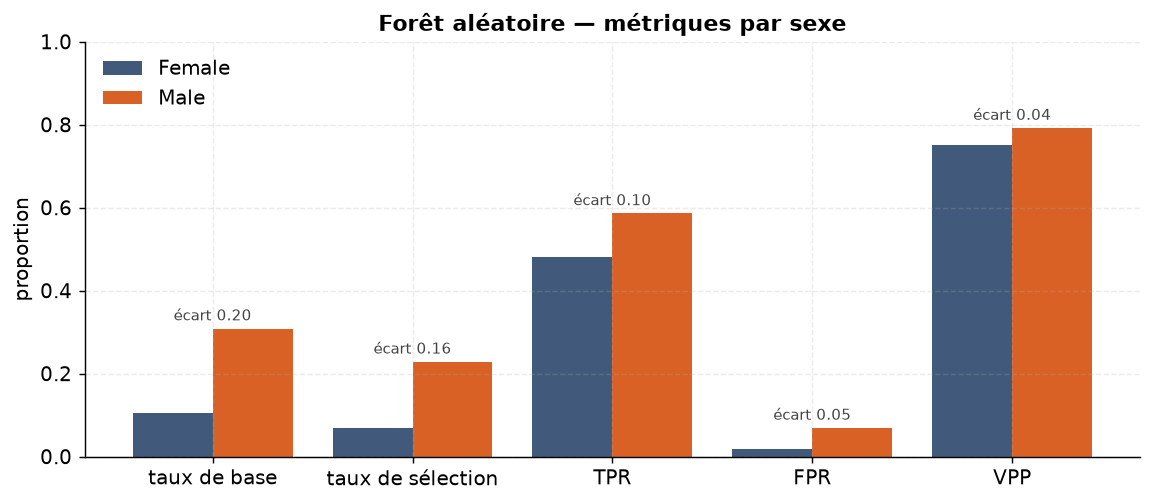

In [47]:
utils.plot_equite_par_groupe(tableau, titre="Forêt aléatoire — métriques par sexe")

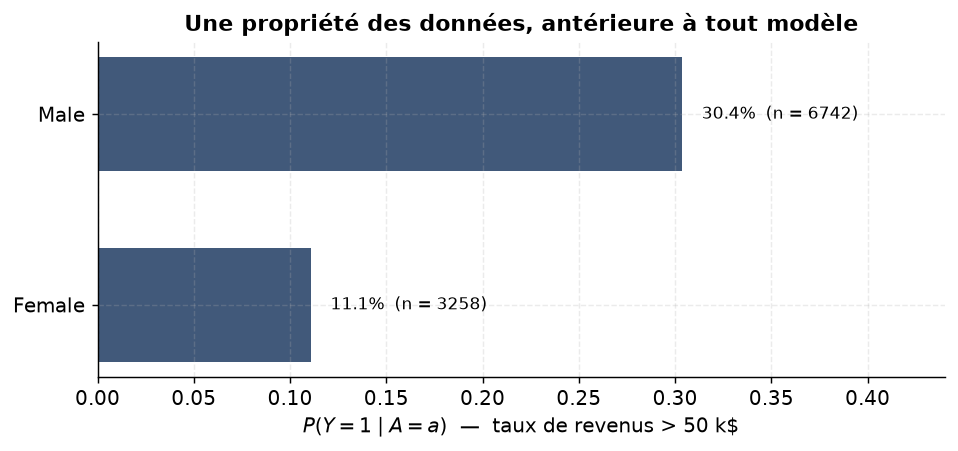

In [48]:
utils.plot_taux_base_adult()

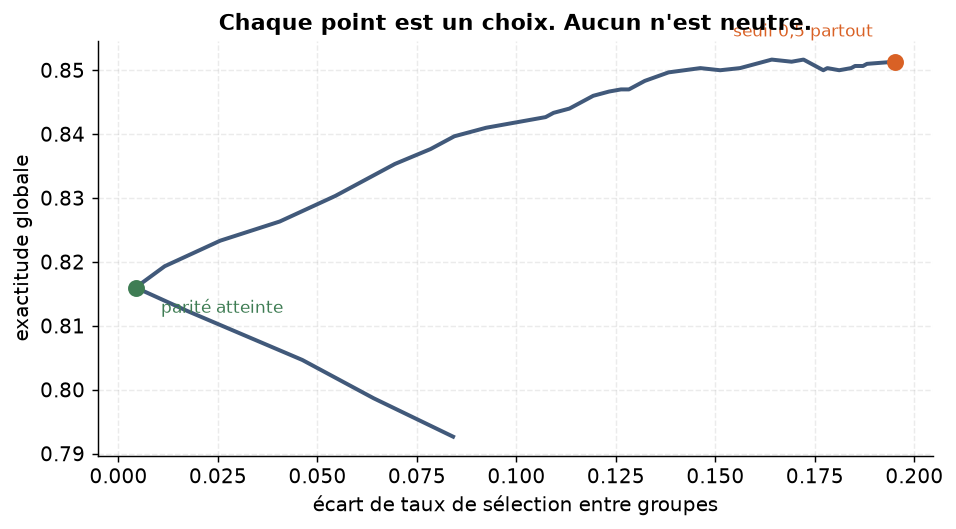

In [49]:
utils.plot_compromis_equite()

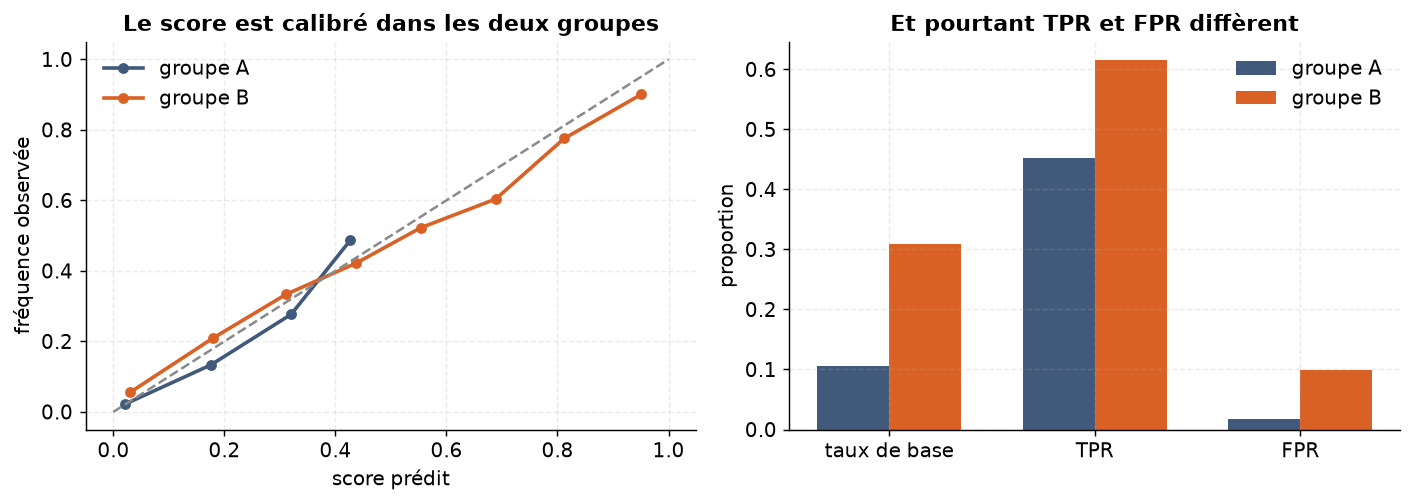

In [50]:
utils.plot_impossibilite()

## 10. Validation temporelle

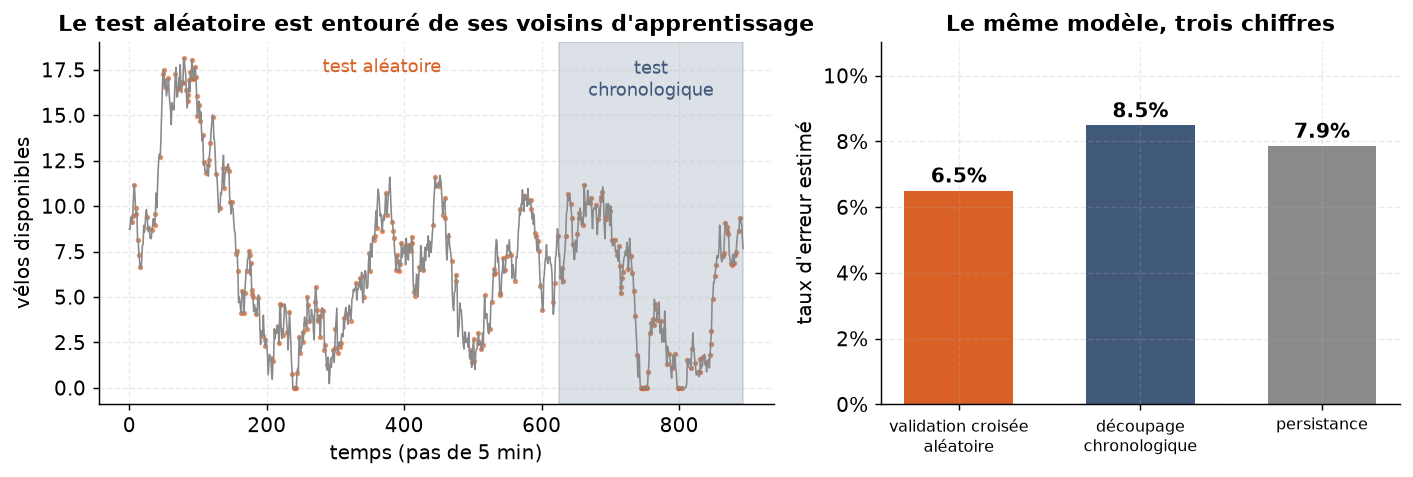

In [51]:
utils.plot_decoupage_temporel()

## 11. Évaluation : matrice de confusion, ROC, précision-rappel

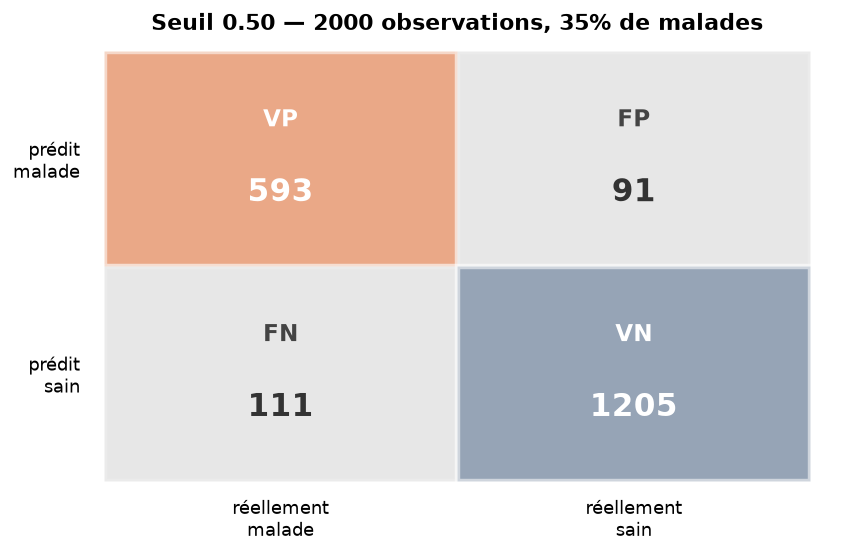

In [52]:
utils.plot_matrice_confusion()

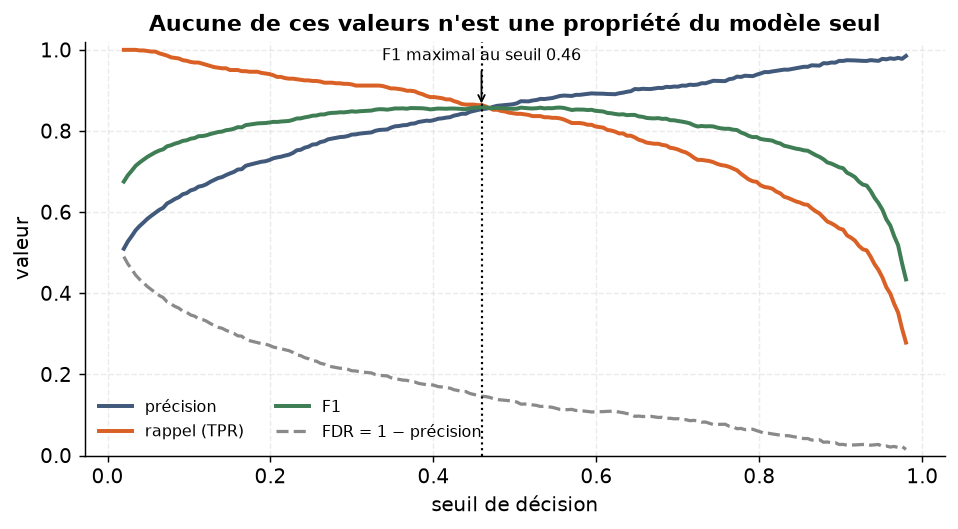

In [53]:
utils.plot_metriques_seuil()

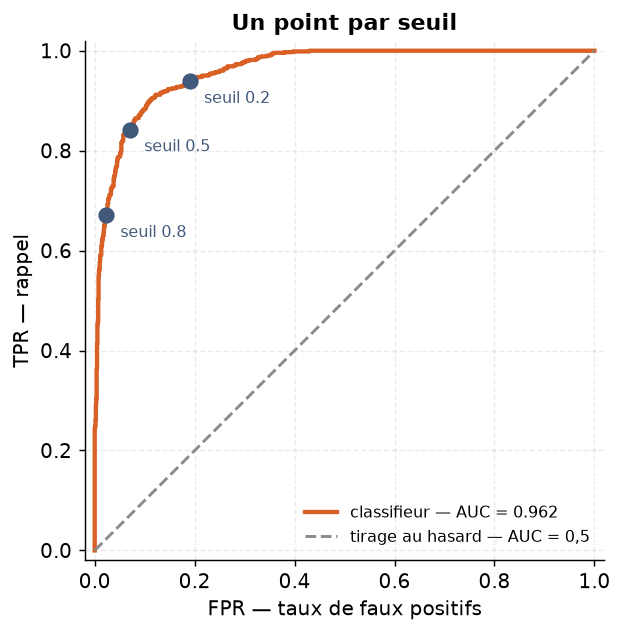

In [54]:
utils.plot_roc()

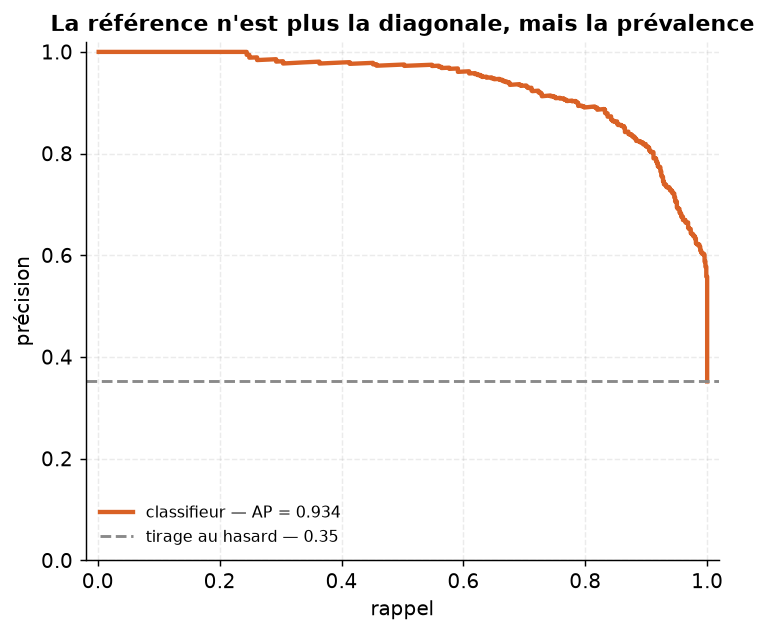

In [55]:
utils.plot_precision_rappel()

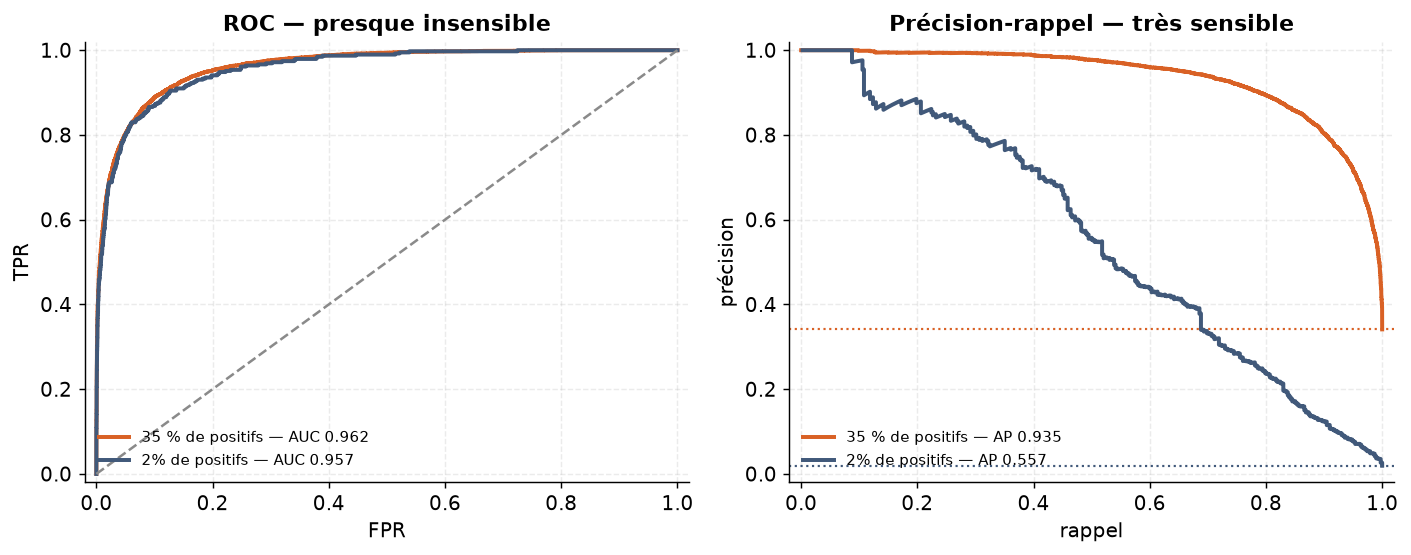

In [56]:
utils.plot_roc_vs_pr()

## Annexe — bibliographie

Ouvrages de référence du cours :

- Hastie, Tibshirani & Friedman — *The Elements of Statistical Learning*, Springer, 2009
- James, Witten, Hastie, Tibshirani & Taylor — *An Introduction to Statistical Learning*, Springer, 2023
- Bishop — *Pattern Recognition and Machine Learning*, Springer, 2006
- Murphy — *Probabilistic Machine Learning: An Introduction*, MIT Press, 2022